# HR Attrition Analysis

## 1. Exploratory Data Analysis (EDA)

The objective of this notebook is to explore employee
data and identify patterns associated with employee
attrition.

We will investigate demographic, compensation,
work environment and career development factors.

## 2. Import Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/cleaned_hr_data.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


## 3. Workforce Overview

In [4]:
total_employees = len(df)

employees_left = (df["Attrition"] == "Yes").sum()

employees_stayed = (df["Attrition"] == "No").sum()

attrition_rate = (employees_left / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print("Attrition Rate:", round(attrition_rate, 2), "%")

Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12 %


## 4. Employee Attrition Distribution

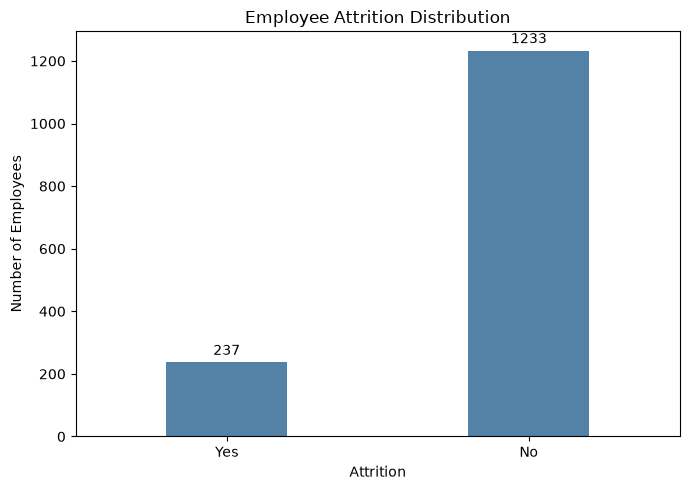

In [11]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Attrition", color="steelblue", width=0.4)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Employee Attrition Distribution", fontsize=12)
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The dataset contains 1,470 employees, of which 237
employees left the organization and 1,233 remained.

The overall attrition rate is 16.12%.

The majority of employees stayed with the organization.

## 5. Department-wise Attrition Analysis

The objective is to identify which departments
experience higher employee turnover.

We will calculate both the number of employees
who left and the attrition percentage.

In [13]:
department_analysis = df.groupby("Department").agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

department_analysis["attrition_rate"] = (
    department_analysis["employees_left"] / department_analysis["total_employees"]
) * 100

department_analysis = department_analysis.sort_values(
    by="attrition_rate", ascending=False
)

display(department_analysis)

,total_employees,employees_left,attrition_rate
Department,,,
Sales,446,92,20.627803
Human Resources,63,12,19.047619
Research & Development,961,133,13.839750


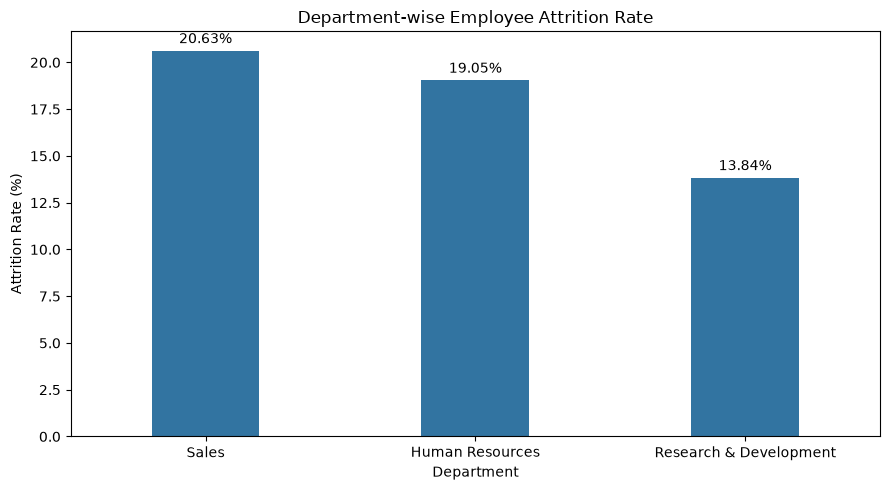

In [ ]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=department_analysis.reset_index(),
    x="Department",
    y="attrition_rate",
    width=0.4,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Department-wise Employee Attrition Rate")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Department-wise Attrition: Key Observations

1. The Sales department has the highest attrition rate at 20.63%.
2. Research & Development has the lowest attrition rate at 13.84%.
3. Research & Development has the highest number of employee departures (133), despite having the lowest attrition rate.
4. Human Resources has an attrition rate of 19.05%, but its smaller workforce of 63 employees should be considered when interpreting this result.

**Business implication:** The Sales department may warrant further investigation into workload, compensation, overtime and job satisfaction. However, these results alone do not establish the reasons for employee turnover.

## 6. Age-wise Attrition Analysis

The objective is to investigate whether employee
attrition rates differ across different age groups.

We will group employees into age categories and
compare their attrition rates.

In [27]:
bins = [17, 25, 35, 45, 55, 60]

labels = ["18-25", "26-35", "36-45", "46-55", "56-60"]

df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)

In [28]:
age_analysis = df.groupby("AgeGroup", observed=True).agg(
    total_employees=("Attrition", "count"),
    employees_left=("Attrition", lambda x: (x == "Yes").sum()),
)

age_analysis["attrition_rate"] = (
    age_analysis["employees_left"] / age_analysis["total_employees"]
) * 100

display(age_analysis)

,total_employees,employees_left,attrition_rate
AgeGroup,,,
18-25,123,44,35.772358
26-35,606,116,19.141914
36-45,468,43,9.188034
46-55,226,26,11.504425
56-60,47,8,17.021277


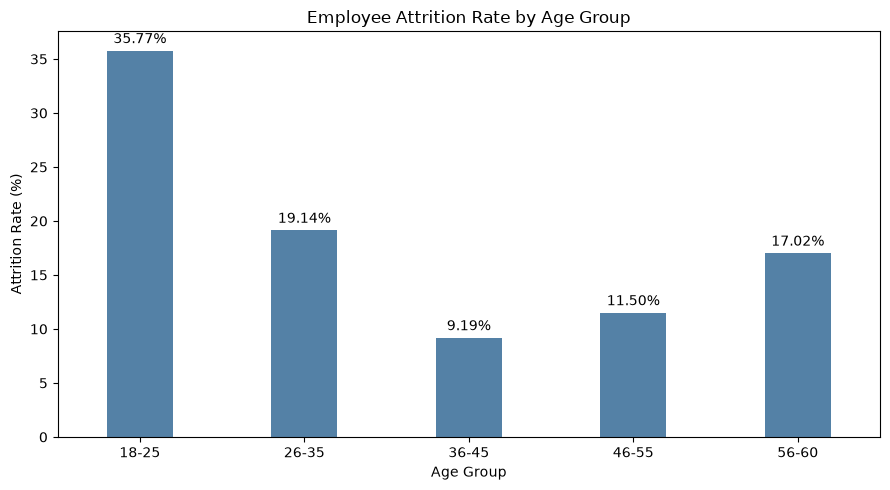

In [29]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_analysis.reset_index(),
    x="AgeGroup",
    y="attrition_rate",
    color="steelblue",
    width=0.4,
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Age-wise Attrition: Key Observations

1. Employees aged 18–25 have the highest attrition rate at 35.77%.
2. Employees aged 36–45 have the lowest attrition rate at 9.19%.
3. The 26–35 age group has the highest number of departures, with 116 employees.
4. The youngest age group has a relatively high attrition rate despite having fewer employees than the 26–35 group.
5. The 56–60 age group has a relatively small sample size, so its attrition rate should be interpreted cautiously.

**Business implication:** The organization should investigate employee retention among early-career workers, including onboarding, career development, compensation and job satisfaction. Further analysis is required before identifying specific explanations.